In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import torch

In [2]:
from graphviz import Digraph


def trace(root):
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges


def draw_dot(root, format="svg", rankdir="LR"):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ["LR", "TB"]
    nodes, edges = trace(root)
    dot = Digraph(
        format=format, graph_attr={"rankdir": rankdir}
    )  # , node_attr={'rankdir': 'TB'})

    for n in nodes:
        dot.node(
            name=str(id(n)),
            label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad),
            shape="record",
        )
        if n._op:
            dot.node(name=str(id(n)) + n._op, label=n._op)
            dot.edge(str(id(n)) + n._op, str(id(n)))

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [3]:
class Value:

    def __init__(self, data, _children=(), _op="", label=""):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward

        return out

    def __radd__(self, other):  # other + self
        return self + other

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward

        return out

    def __rmul__(self, other):  # other * self
        return self * other

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers"
        out = Value(self.data**other, (self,), f"**{other}")

        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad

        out._backward = _backward

        return out

    def __truediv__(self, other):  # self / other
        return self * other**-1

    def __neg__(self):  # -self
        return self * -1

    def __sub__(self, other):  # self - other
        return self + (-other)

    def tahn(self):
        x = self.data
        t = (math.exp(2 * x) - 1) / (math.exp(2 * x) + 1)
        out = Value(t, (self,), "tahn")

        def _backward():
            self.grad += (1 - t**2) * out.grad

        out._backward = _backward

        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), "exp")

        def _backward():
            self.grad += out.data * out.grad

        out._backward = _backward

        return out

    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

---
*01:39:31 doing the same thing but in PyTorch: comparison*

In [4]:
import torch

x1 = torch.Tensor([2.0]).double()
x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()
x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()
w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()
w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()
b.requires_grad = True
n = x1 * w1 + x2 * w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print("---")
print("x1", x1.grad.item())
print("w1", w2.grad.item())
print("x2", x2.grad.item())
print("w2", w2.grad.item())

0.7071066904050358
---
x1 -1.5000003851533106
w1 0.0
x2 0.5000001283844369
w2 0.0


---
*01:43:55 building out a neural net library (multi-layer perceptron) in micrograd*

In [5]:
class Neuron:
    """A neuron is a sequence of weights and a bias"""

    def __init__(self, nin, label=""):
        """nin - number of inputs"""

        self.label = label
        self.w = [
            Value(random.uniform(-1, 1), label=f"{self.label}-W{i}") for i in range(nin)
        ]
        self.b = Value(random.uniform(-1, 1), label=f"{self.label}-B")

    def __call__(self, x):
        """x - input, a sequence of float numbers"""
        # forward pass
        act = sum(wi * xi for wi, xi in zip(self.w, x)) + self.b  # activation
        out = act.tahn()  # normalization
        return out

    def parameters(self):
        return self.w + [self.b]


class Layer:
    """A layer is a sequence of Neurons."""

    def __init__(self, nin, nout, label=""):
        self.label = label
        self.neurons = [Neuron(nin, label=f"{self.label}-N{i}") for i in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]


class MLP:
    """MPL - multi layer perception"""

    def __init__(self, nin, nouts):
        """
        nin: number of inputs
        nouts: a list of number of neurons in each layer
        """
        sz = [nin] + nouts
        self.layers = [
            Layer(sz[i], sz[i + 1], label=f"L{i}") for i in range(len(nouts))
        ]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x
    
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [6]:
x = [2.0, 3.0, -1.0]  # input

# MLP - input layer 3; hidden layers 2 (4, 4); output layer 1;
# Input layer - 3 inputs
# Hidden layer 1 - 4 neurons - inputs 3, outputs 4
# Hidden layer 2 - 4 neurons - inputs 4, outputs 1
# Output layer - 1 output
n = MLP(3, [4, 4, 1])  # mlp

n(x)

Value(data=0.8490121214396347)

In [7]:
len(n.parameters()), n.parameters()

(41,
 [Value(data=-0.6462538281059653),
  Value(data=-0.10662285994818221),
  Value(data=-0.5994073892893867),
  Value(data=0.31251665867507983),
  Value(data=0.5756083845231639),
  Value(data=0.24358217185713715),
  Value(data=-0.5595655368710342),
  Value(data=0.993844258024569),
  Value(data=0.33630606845367184),
  Value(data=-0.07820789693679431),
  Value(data=0.1571366581716298),
  Value(data=-0.11708489178438342),
  Value(data=-0.8770990702300034),
  Value(data=-0.025684536990953966),
  Value(data=-0.4228782791485626),
  Value(data=-0.24421772529103714),
  Value(data=-0.46496848758343146),
  Value(data=0.40812840784802007),
  Value(data=0.6741061799261956),
  Value(data=-0.35432846479879143),
  Value(data=-0.026914815656250868),
  Value(data=0.4430319424567115),
  Value(data=0.31855404086015393),
  Value(data=0.05111518572108986),
  Value(data=-0.8217661365162343),
  Value(data=0.4931806292285166),
  Value(data=0.9047019478695983),
  Value(data=0.3677253809055947),
  Value(data=0

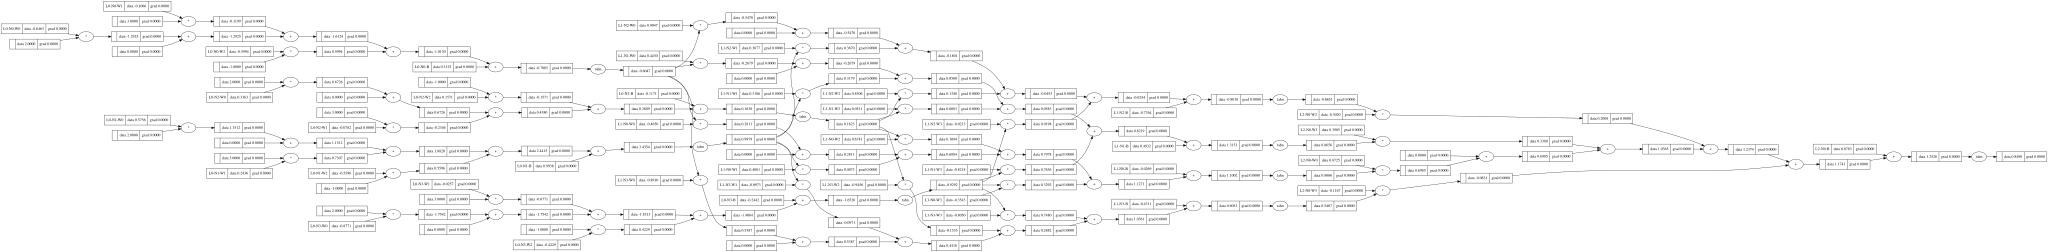

In [8]:
draw_dot(n(x))

---
*01:51:04 creating a tiny dataset, writing the loss function*

In [9]:
# dataset
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]

# target - desired targets
ys = [1.0, -1.0, -1.0, 1.0]

In [10]:
# predictions
# ypred = [n(x) for x in xs]

# loss - the closer to zero or zero, it's good
# for a single prediction, if a prediction isn't equal to target,
# this is a bad result - we mesure it with loss function

# the loss is the sum of squared difference between prediction and ground through (here ygt)
# for each single (yout - ygt) is it's close to zero than it's good, otherwise it's bad ->
# we should decrease it (decrease the loss).
# Increase it's not an option because with **2 we don't have negative numbers

# loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])
# ypred,loss

In [11]:
for k in range(20):
    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum([(yout - ygt) ** 2 for ygt, yout in zip(ys, ypred)])

    # zero out gradients (start with fresh grads before each backpropagation)
    for p in n.parameters():
        p.grad = 0.0

    # backward pass
    loss.backward()

    # update (minimize the loss)
    for p in n.parameters():
        p.data += -0.1 * p.grad  # negative 0.01 because we want to decrease the loss

    print(k, loss.data)

ys, ypred

0 6.961385597023095
1 5.538919031647339
2 3.8530474746511816
3 3.348539300352485
4 2.561118798393698
5 3.8094770148855854
6 1.5052144531755807
7 0.015436036988970621
8 0.014643764032068504
9 0.013930826383859046
10 0.013285599955423732
11 0.012698661724766757
12 0.012162286939395299
13 0.011670079048284139
14 0.011216693026462965
15 0.010797625578218202
16 0.010409053999376479
17 0.010047710957823563
18 0.009710786139531781
19 0.009395848233462354


([1.0, -1.0, -1.0, 1.0],
 [Value(data=0.9497601797352346),
  Value(data=-0.9547648229631058),
  Value(data=-0.9570790808395545),
  Value(data=0.9453796544308829)])